# Zajęcia 2 — Sieci rekurencyjne: budowa i uczenie

**Cel:** zaimplementować prosty RNN w PyTorch i nauczyć go przewidywać kolejną
próbkę szeregu czasowego (sygnał sinusoidalny z szumem). Zbadać krzywą uczenia
oraz wpływ typu komórki (RNN/LSTM/GRU), liczby jednostek i długości okna.

Uruchamiaj komórki po kolei (Shift+Enter).

*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*

## 1. Instalacja i import

In [1]:
!pip -q install torch numpy matplotlib

In [2]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Urządzenie:', DEVICE)

Urządzenie: cuda


## 2. Dane: szereg czasowy

Generujemy sygnał sinusoidalny z niewielkim szumem — prosty, powtarzalny szereg,
na którym łatwo zobaczyć, czy sieć nauczyła się struktury.

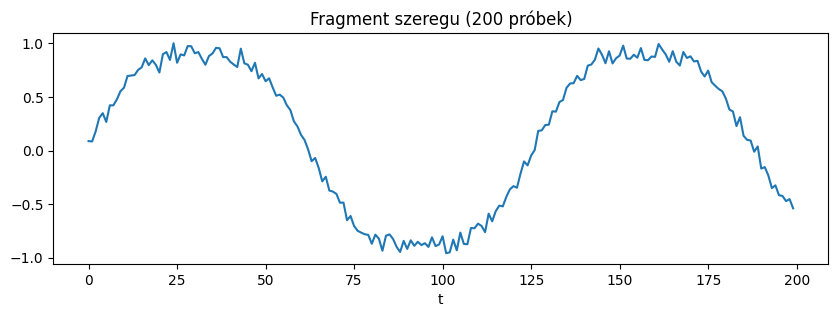

In [3]:
def generuj_szereg(n=2000):
    t = np.linspace(0, 100, n)
    y = np.sin(t) + 0.1*np.sin(3*t) + 0.05*np.random.randn(n)
    return y.astype(np.float32)

seria = generuj_szereg()
plt.figure(figsize=(10,3))
plt.plot(seria[:200])
plt.title('Fragment szeregu (200 próbek)'); plt.xlabel('t'); plt.show()

## 3. Okna wejście–cel

Z ciągu tworzymy przykłady uczące: **okno** kolejnych próbek jako wejście,
a następna próbka jako cel (zadanie *sequence-to-vector*).

In [4]:
def zrob_okna(seria, okno=30):
    X, Y = [], []
    for i in range(len(seria)-okno):
        X.append(seria[i:i+okno]); Y.append(seria[i+okno])
    X = np.array(X, dtype=np.float32)[..., None]  # [N, okno, 1]
    Y = np.array(Y, dtype=np.float32)[:, None]     # [N, 1]
    return X, Y

OKNO = 30
X, Y = zrob_okna(seria, OKNO)

# Podział chronologiczny (bez tasowania — to szereg czasowy!)
n_tr = int(0.8*len(X))
Xtr = torch.tensor(X[:n_tr]).to(DEVICE); Ytr = torch.tensor(Y[:n_tr]).to(DEVICE)
Xte = torch.tensor(X[n_tr:]).to(DEVICE); Yte = torch.tensor(Y[n_tr:]).to(DEVICE)
print('Trening:', Xtr.shape, ' Test:', Xte.shape)

Trening: torch.Size([1576, 30, 1])  Test: torch.Size([394, 30, 1])


## 4. Model RNN

Jedna warstwa rekurencyjna + warstwa liniowa na ostatnim stanie ukrytym.
Parametr `typ` przełącza SimpleRNN / LSTM / GRU.

In [5]:
class ModelRNN(nn.Module):
    def __init__(self, hidden=32, typ='RNN'):
        super().__init__()
        rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ]
        self.rnn = rnn(input_size=1, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])   # ostatni krok -> predykcja

## 5. Pętla uczenia

In [24]:
import time

def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=30, lr=1e-2, batch=64):
    t_start = time.time()
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    strata = nn.MSELoss()
    hist = []
    hist_train = []
    n = len(Xtr)
    for ep in range(epoki):
        model.train(); perm = torch.randperm(n)
        strata_epoki = 0.0
        for i in range(0, n, batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            loss = strata(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            strata_epoki += loss.item() * len(idx)
        hist_train.append(strata_epoki / n)

        model.eval()
        with torch.no_grad():
            hist.append(strata(model(Xte), Yte).item())
    t_end = time.time()
    return hist, hist_train, t_end - t_start

t_start_heur = time.time()
mse_heur = ((Yte - Xte[:, -1])**2).mean().item()
t_end_heur = time.time()
czas_heur = t_end_heur - t_start_heur

print(f"MSE heurystyki 'ostatnia próbka': {mse_heur:.4f} | czas = {czas_heur:.6f} s")

model = ModelRNN(hidden=32, typ='RNN')
hist, hist_train, czas_baza = trenuj(model, Xtr, Ytr, Xte, Yte, epoki=20)
print(f"Test MSE modelu bazowego (RNN, hidden=32, OKNO=30): {np.mean(hist[-5:]):.4f}")
print(f"Czas treningu modelu bazowego: {czas_baza:.2f} s\n")

MSE heurystyki 'ostatnia próbka': 0.0063 | czas = 0.000917 s
Test MSE modelu bazowego (RNN, hidden=32, OKNO=30): 0.0040
Czas treningu modelu bazowego: 1.19 s



## 6. Krzywa uczenia

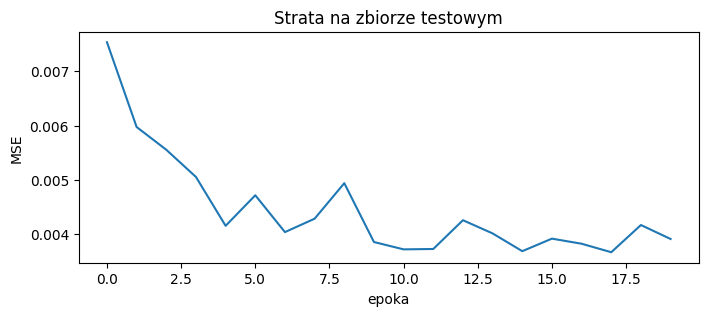

In [9]:
plt.figure(figsize=(8,3))
plt.plot(hist)
plt.title('Strata na zbiorze testowym'); plt.xlabel('epoka'); plt.ylabel('MSE'); plt.show()

## 7. Predykcja vs rzeczywistość

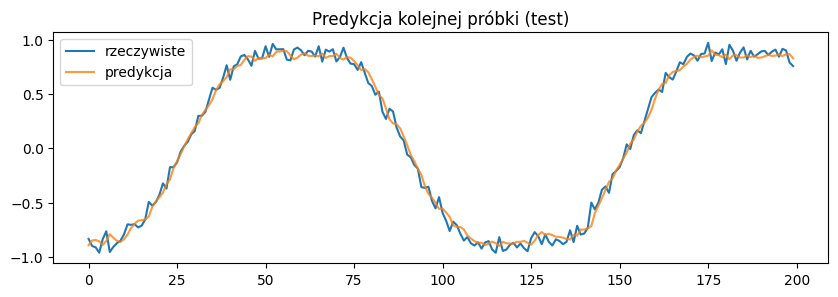

In [10]:
model.eval()
with torch.no_grad():
    pred = model(Xte).cpu().numpy().ravel()
prawdziwe = Yte.cpu().numpy().ravel()

plt.figure(figsize=(10,3))
plt.plot(prawdziwe[:200], label='rzeczywiste')
plt.plot(pred[:200], label='predykcja', alpha=0.8)
plt.legend(); plt.title('Predykcja kolejnej próbki (test)'); plt.show()

## 8. Eksperyment: typ komórki oraz liczba jednostek

Porównanie SimpleRNN/LSTM/GRU i wpływu rozmiaru stanu ukrytego.

In [11]:
print('Typ komórki (hidden=32):')
for typ in ['RNN','LSTM','GRU']:
    h, _ = trenuj(ModelRNN(hidden=32, typ=typ), Xtr, Ytr, Xte, Yte, epoki=20)
    print(f'  {typ:5s} test MSE = {h[-1]:.4f}')

print('Liczba jednostek (GRU):')
for hs in [8, 32, 64]:
    h, _ = trenuj(ModelRNN(hidden=hs, typ='GRU'), Xtr, Ytr, Xte, Yte, epoki=20)
    print(f'  hidden={hs:3d} test MSE = {h[-1]:.4f}')

Typ komórki (hidden=32):
  RNN   test MSE = 0.0047
  LSTM  test MSE = 0.0036
  GRU   test MSE = 0.0033
Liczba jednostek (GRU):
  hidden=  8 test MSE = 0.0037
  hidden= 32 test MSE = 0.0033
  hidden= 64 test MSE = 0.0033


## Zadanie na sprawozdanie

1. Zbadaj wpływ **liczby jednostek ukrytych** i **długości okna** (`OKNO`) na jakość predykcji.
2. Dla co najmniej trzech konfiguracji podaj test MSE w tabeli i dołącz krzywe uczenia.
3. Porównaj SimpleRNN, LSTM i GRU — który uczy się szybciej/stabilniej?
4. Wnioski: kiedy większy model/okno pomaga, a kiedy nie?

Format sprawozdania: `00_materialy_wspolne/szablon_sprawozdania.md`.

In [20]:
def wykonaj_eksperyment(seria, typ, hidden, okno, epoki=20):
    X, Y = zrob_okna(seria, okno)
    n_tr = int(0.8*len(X))
    Xtr_exp = torch.tensor(X[:n_tr]).to(DEVICE)
    Ytr_exp = torch.tensor(Y[:n_tr]).to(DEVICE)
    Xte_exp = torch.tensor(X[n_tr:]).to(DEVICE)
    Yte_exp = torch.tensor(Y[n_tr:]).to(DEVICE)

    wyniki_mse = []
    czasy = []
    for ziarno in [0, 1, 2]:
        torch.manual_seed(ziarno)
        np.random.seed(ziarno)

        model = ModelRNN(hidden=hidden, typ=typ)
        hist, _, t_time = trenuj(model, Xtr_exp, Ytr_exp, Xte_exp, Yte_exp, epoki=epoki)
        wyniki_mse.append(np.mean(hist[-5:]))
        czasy.append(t_time)

    return np.mean(wyniki_mse), np.std(wyniki_mse), np.mean(czasy)

In [21]:
# 2. Eksperyment A: liczba jednostek
print("Eksperyment A (GRU, stałe OKNO=30):")
for hs in [8, 16, 32, 64]:
    srednia, odchylenie, t_srednia = wykonaj_eksperyment(seria, 'GRU', hs, 30)
    print(f"  hidden={hs:<2d} | test MSE = {srednia:.4f} +/- {odchylenie:.4f} | czas = {t_srednia:.2f} s")

Eksperyment A (GRU, stałe OKNO=30):
  hidden=8  | test MSE = 0.0038 +/- 0.0000 | czas = 1.23 s
  hidden=16 | test MSE = 0.0037 +/- 0.0000 | czas = 1.26 s
  hidden=32 | test MSE = 0.0038 +/- 0.0000 | czas = 1.27 s
  hidden=64 | test MSE = 0.0038 +/- 0.0001 | czas = 1.27 s


In [22]:
# 3. Eksperyment B: długość okna
print("\nEksperyment B (GRU, stałe hidden=32):")
for o in [10, 30, 60, 120]:
    srednia, odchylenie, t_srednia = wykonaj_eksperyment(seria, 'GRU', 32, o)
    print(f"  OKNO={o:<3d} | test MSE = {srednia:.4f} +/- {odchylenie:.4f} | czas = {t_srednia:.2f} s")


Eksperyment B (GRU, stałe hidden=32):
  OKNO=10  | test MSE = 0.0041 +/- 0.0002 | czas = 1.28 s
  OKNO=30  | test MSE = 0.0038 +/- 0.0000 | czas = 1.33 s
  OKNO=60  | test MSE = 0.0034 +/- 0.0002 | czas = 1.35 s
  OKNO=120 | test MSE = 0.0034 +/- 0.0002 | czas = 1.38 s


In [23]:
print("\nEksperyment C (stałe hidden=32, OKNO 10 i 120):")
for o in [10, 120]:
    for t in ['RNN', 'LSTM', 'GRU']:
        srednia, odchylenie, t_srednia = wykonaj_eksperyment(seria, t, 32, o)
        print(f"  {t:4s} OKNO={o:<3d} | test MSE = {srednia:.4f} +/- {odchylenie:.4f} | czas = {t_srednia:.2f} s")


Eksperyment C (stałe hidden=32, OKNO 10 i 120):
  RNN  OKNO=10  | test MSE = 0.0042 +/- 0.0002 | czas = 1.18 s
  LSTM OKNO=10  | test MSE = 0.0042 +/- 0.0001 | czas = 1.35 s
  GRU  OKNO=10  | test MSE = 0.0041 +/- 0.0002 | czas = 1.34 s
  RNN  OKNO=120 | test MSE = 0.0040 +/- 0.0000 | czas = 1.17 s
  LSTM OKNO=120 | test MSE = 0.0037 +/- 0.0001 | czas = 1.55 s
  GRU  OKNO=120 | test MSE = 0.0034 +/- 0.0002 | czas = 1.27 s


### Wizualizacja wyników eksperymentów oraz analiza najlepszego modelu

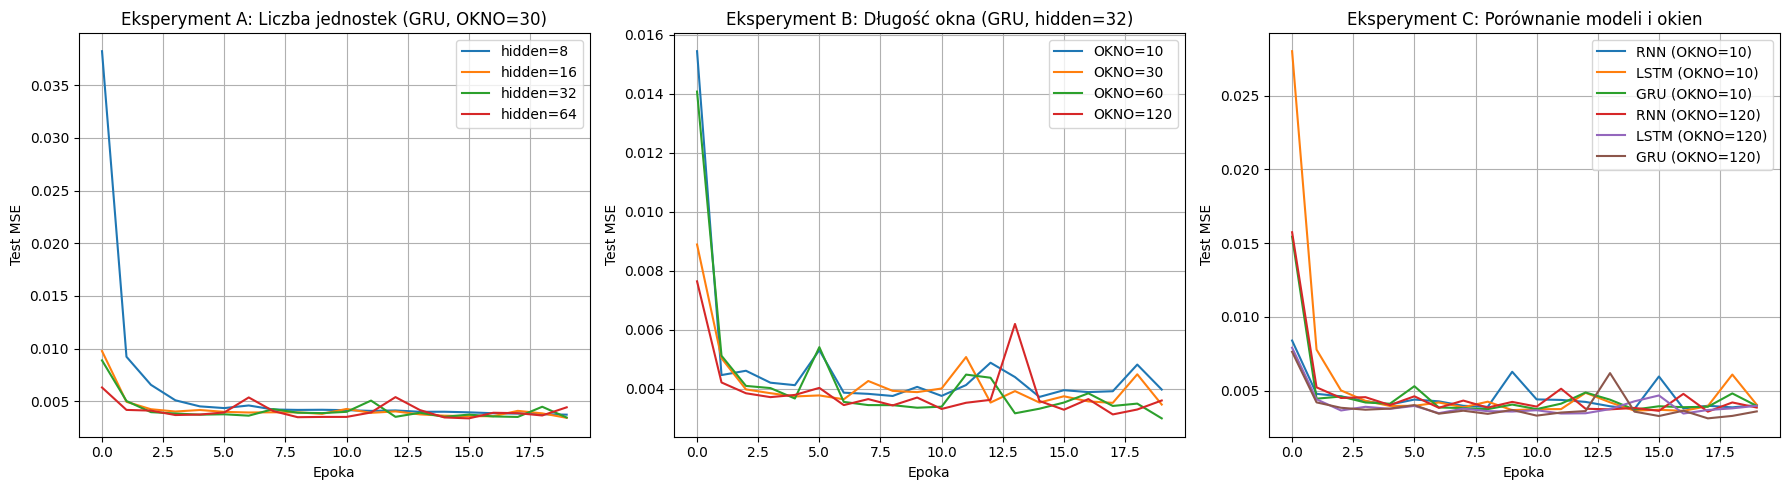

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import torch

plt.figure(figsize=(18, 5))

# 1. Eksperyment A: liczba jednostek (GRU, OKNO=30)
plt.subplot(1, 3, 1)
for hs in [8, 16, 32, 64]:
    # Przygotowanie danych bezpośrednio
    X_win, Y_win = zrob_okna(seria, 30)
    n_tr_curr = int(0.8 * len(X_win))
    Xtr_curr = torch.tensor(X_win[:n_tr_curr]).to(DEVICE)
    Ytr_curr = torch.tensor(Y_win[:n_tr_curr]).to(DEVICE)
    Xte_curr = torch.tensor(X_win[n_tr_curr:]).to(DEVICE)
    Yte_curr = torch.tensor(Y_win[n_tr_curr:]).to(DEVICE)

    torch.manual_seed(0)
    model = ModelRNN(hidden=hs, typ='GRU')
    hist, _ = trenuj(model, Xtr_curr, Ytr_curr, Xte_curr, Yte_curr, epoki=20)
    plt.plot(hist, label=f'hidden={hs}')

plt.title('Eksperyment A: Liczba jednostek (GRU, OKNO=30)')
plt.xlabel('Epoka')
plt.ylabel('Test MSE')
plt.legend()
plt.grid(True)

# 2. Eksperyment B: długość okna (GRU, hidden=32)
plt.subplot(1, 3, 2)
for o in [10, 30, 60, 120]:
    X_win, Y_win = zrob_okna(seria, o)
    n_tr_curr = int(0.8 * len(X_win))
    Xtr_curr = torch.tensor(X_win[:n_tr_curr]).to(DEVICE)
    Ytr_curr = torch.tensor(Y_win[:n_tr_curr]).to(DEVICE)
    Xte_curr = torch.tensor(X_win[n_tr_curr:]).to(DEVICE)
    Yte_curr = torch.tensor(Y_win[n_tr_curr:]).to(DEVICE)

    torch.manual_seed(0)
    model = ModelRNN(hidden=32, typ='GRU')
    hist, _ = trenuj(model, Xtr_curr, Ytr_curr, Xte_curr, Yte_curr, epoki=20)
    plt.plot(hist, label=f'OKNO={o}')

plt.title('Eksperyment B: Długość okna (GRU, hidden=32)')
plt.xlabel('Epoka')
plt.ylabel('Test MSE')
plt.legend()
plt.grid(True)

# 3. Eksperyment C: porównanie modeli (hidden=32, OKNO 10 vs 120)
plt.subplot(1, 3, 3)
for o in [10, 120]:
    for t in ['RNN', 'LSTM', 'GRU']:
        X_win, Y_win = zrob_okna(seria, o)
        n_tr_curr = int(0.8 * len(X_win))
        Xtr_curr = torch.tensor(X_win[:n_tr_curr]).to(DEVICE)
        Ytr_curr = torch.tensor(Y_win[:n_tr_curr]).to(DEVICE)
        Xte_curr = torch.tensor(X_win[n_tr_curr:]).to(DEVICE)
        Yte_curr = torch.tensor(Y_win[n_tr_curr:]).to(DEVICE)

        torch.manual_seed(0)
        model = ModelRNN(hidden=32, typ=t)
        hist, _ = trenuj(model, Xtr_curr, Ytr_curr, Xte_curr, Yte_curr, epoki=20)
        plt.plot(hist, label=f'{t} (OKNO={o})')

plt.title('Eksperyment C: Porównanie modeli i okien')
plt.xlabel('Epoka')
plt.ylabel('Test MSE')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

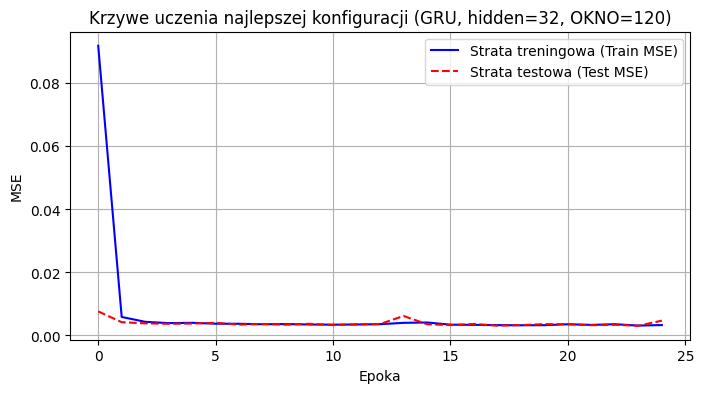

In [17]:
# --- NAJLEPSZA KONFIGURACJA: GRU, OKNO=120, hidden=32 ---
X_win, Y_win = zrob_okna(seria, 120)
n_tr_best = int(0.8 * len(X_win))
Xtr_best = torch.tensor(X_win[:n_tr_best]).to(DEVICE)
Ytr_best = torch.tensor(Y_win[:n_tr_best]).to(DEVICE)
Xte_best = torch.tensor(X_win[n_tr_best:]).to(DEVICE)
Yte_best = torch.tensor(Y_win[n_tr_best:]).to(DEVICE)

torch.manual_seed(0)
best_model = ModelRNN(hidden=32, typ='GRU')
hist_test_best, hist_train_best = trenuj(best_model, Xtr_best, Ytr_best, Xte_best, Yte_best, epoki=25)

# Wykres krzywych straty (treningowej i testowej)
plt.figure(figsize=(8, 4))
plt.plot(hist_train_best, label='Strata treningowa (Train MSE)', color='blue')
plt.plot(hist_test_best, label='Strata testowa (Test MSE)', color='red', linestyle='--')
plt.title('Krzywe uczenia najlepszej konfiguracji (GRU, hidden=32, OKNO=120)')
plt.xlabel('Epoka')
plt.ylabel('MSE')
plt.legend()
plt.grid(True)
plt.show()

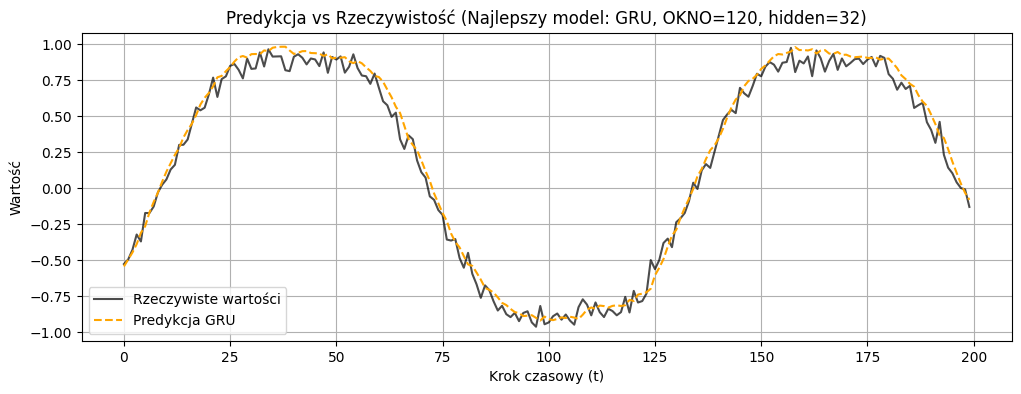

In [18]:
# Wykres predykcji na tle rzeczywistego przebiegu dla najlepszej konfiguracji
best_model.eval()
with torch.no_grad():
    pred_best = best_model(Xte_best).cpu().numpy().ravel()
prawdziwe_best = Yte_best.cpu().numpy().ravel()

plt.figure(figsize=(12, 4))
plt.plot(prawdziwe_best[:200], label='Rzeczywiste wartości', color='black', alpha=0.7)
plt.plot(pred_best[:200], label='Predykcja GRU', color='orange', linestyle='--')
plt.title('Predykcja vs Rzeczywistość (Najlepszy model: GRU, OKNO=120, hidden=32)')
plt.xlabel('Krok czasowy (t)')
plt.ylabel('Wartość')
plt.legend()
plt.grid(True)
plt.show()